In [158]:
from __future__ import annotations
import sys
from pathlib import Path
from tqdm import trange
import numpy as np
ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / 'hidden_sector_DM').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from hidden_sector_DM.HiddenSectorDM import VectorPortal, BaryonPortal, HiggsPortal 

from GCE.likelihood import cascade_template, gls_fit, measurement   # noqa: E402
from GCE.pythia_runner import DEFAULT_SEED                     # noqa: E402
from scipy.ndimage import shift as ndimage_shift
from GCE.halo import HALO_2112, RHO_LOCAL_PRIOR
import numpy as np
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.path import Path as MplPath
from matplotlib.tri import Triangulation, LinearTriInterpolator
from scipy.ndimage import gaussian_filter, gaussian_filter1d
import time
from hidden_sector_DM.HiddenSectorDM import Cosmology, BoltzmannSolver, s0_cosmo, rhoc
from GCE.spectrum import GEVM2_TO_CM3S
from scipy.optimize import brentq
from scipy.interpolate import griddata
plt.style.use(ROOT / 'notebooks' / 'mine.mplstyle')
plt.rcParams['axes.axisbelow'] = False

In [159]:
# ---- the fits, written by GCE/scripts/make_GCE_sv_grids.py ---------------
REGION = "south"        # 'both' (40x40), 'south' or 'north'
portals = ['vP','bP', 'blP', 'hP']
SV_DIR = ROOT / 'GCE' / 'output' / 'sv_fits'
SV_RELIC_DIR = ROOT / 'GCE' / 'output' / 'sv_relic_fits'

fits = {name: dict(np.load(SV_DIR / f'GCE_sv_grid_{name}_{REGION}.npz'))
        for name in portals}
MX_GRID, MY_GRID = fits['vP']['mX'], fits['vP']['mY']   # the same grid in every file
n_pts = MX_GRID.size

for name, fit in fits.items():
    k = int(np.nanargmin(fit['chi2']))
    fit['k_best'] = k
    print(f"{name:4s} best fit: mX={MX_GRID[k]:g}, mY={MY_GRID[k]:g}, "
          f"chi2={fit['chi2'][k]:.2f} / {14 - 3} dof")

vP   best fit: mX=32.94, mY=20.01, chi2=18.05 / 11 dof
bP   best fit: mX=40.25, mY=21.6, chi2=18.85 / 11 dof
blP  best fit: mX=27.8, mY=16.88, chi2=18.95 / 11 dof
hP   best fit: mX=80.58, mY=76.89, chi2=15.60 / 11 dof


In [160]:
# ============================================================================
# (mX, <sigma v>) region with the local DM density uncertainty folded into the
# chi2, so the contour inflates smoothly instead of being widened by hand into a
# flat-topped band.  Self-contained: rebuilds the fixed-halo surface on its own
# (wide) <sigma v> axis, then profiles rho_local out of it.
# ============================================================================
sigmav_axis = np.logspace(-27, -24, 700)
sigmav_log_step = np.diff(np.log(sigmav_axis))[0]
mx_columns = np.unique(MX_GRID)

# rho_local prior -> chi2 penalty on the log Jbar rescaling.
rho_mean, rho_sigma = RHO_LOCAL_PRIOR # (0.44, 0.13) GeV/cm^3
rho_lognormal_width = rho_sigma / rho_mean
rho_samples = rho_mean * np.exp(np.linspace(-4, 4, 201) * rho_lognormal_width)
ln_jbar_offset = 2.0 * np.log(rho_samples / HALO_2112["rho_local"])          # u
halo_penalty = (np.log(rho_samples / rho_mean) / rho_lognormal_width) ** 2   # P(u)

def sv_region(chi2, sigmav, sigmav_err, desc=None):
    """(chi2_fixed_halo, chi2_profiled) on the (sigmav_axis, mx_columns)
    mesh, each mX column minimised over mY."""
    chi2_fixed_halo = np.full((sigmav_axis.size, mx_columns.size), np.nan)
    for j in trange(len(mx_columns), desc=desc):
        mx=mx_columns[j]
        in_column = ((MX_GRID == mx) & np.isfinite(chi2)
                     & np.isfinite(sigmav) & np.isfinite(sigmav_err))
        if not in_column.any():
            continue
        sv_hat, sv_err, chi2_min = (sigmav[in_column], sigmav_err[in_column],
                                    chi2[in_column])
        parabola = chi2_min + ((sigmav_axis[:, None] - sv_hat) / sv_err) ** 2
        chi2_fixed_halo[:, j] = parabola.min(axis=1)

    chi2_profiled = np.full_like(chi2_fixed_halo, np.inf)
    for u, penalty in zip(ln_jbar_offset, halo_penalty):
        shifted = ndimage_shift(chi2_fixed_halo, (-u / sigmav_log_step, 0),
                                order=1, cval=np.inf, mode="constant")
        np.minimum(chi2_profiled, shifted + penalty, out=chi2_profiled)
    return chi2_fixed_halo, chi2_profiled

for name, fit in fits.items():
    chi2_fixed_halo, chi2_profiled = sv_region(fit['chi2'], fit['sigmav'],
                                                   fit['sigmav_err'], desc=name)
    fit['dchi2_fixed_halo'] = chi2_fixed_halo - np.nanmin(chi2_fixed_halo)
    fit['dchi2_profiled'] = chi2_profiled - np.nanmin(chi2_profiled)

hP: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 124/124 [00:00<00:00, 1938.37it/s]


In [161]:
phi, Cinv = measurement(region=REGION)  
def sv_relic_region(relic_info, mod_info):
    sv_relic=relic_info['sigmav_relic']
    fin = np.isfinite(sv_relic)
    ts=mod_info['ts'][fin]
    # chi2(s) = s^2 tCt - 2 s tCphi + phiCphi exactly, clamped points included
    tCt = np.einsum('ij,jk,ik->i', ts, Cinv, ts)
    tCphi = ts @ Cinv @ phi
    phiCphi = phi @ Cinv @ phi
    chi2_min = mod_info['chi2'][mod_info['k_best']]
    dchi2_relic = np.full(n_pts, np.nan)
    dchi2_relic[fin] = sv_relic[fin] ** 2 * tCt - 2.0 * sv_relic[fin] * tCphi + phiCphi - chi2_min
    # rho_sun only rescales what the GCE sees of the relic: s_eff = sv_relic (rho/0.4)^2
    s_eff = sv_relic[fin] [:, None] * np.exp(ln_jbar_offset)[None, :]
    chi2_rho = s_eff ** 2 * tCt[:, None] - 2.0 * s_eff * tCphi[:, None] + phiCphi
    dchi2_relic_profiled = np.full(n_pts, np.nan)
    dchi2_relic_profiled[fin] = (chi2_rho + halo_penalty).min(axis=1) - chi2_min
    return dchi2_relic, dchi2_relic_profiled

fits_relic = {name: dict(np.load(SV_RELIC_DIR / f'GCE_sv_thermal_relic_grid_{name}.npz'))
              for name in portals}
for name in portals:
    fits_relic[name]['dchi2_fixed_halo'], fits_relic[name]['dchi2_profiled'] =sv_relic_region(fits_relic[name], fits[name])

In [162]:
def smoothed_field(mX, mY, dchi2, n_interp=400, sigma=0.5, rezero=True):
    """Delta-chi2 on a regular log grid, lightly smoothed.

    Triangulates in log10 space, interpolates, then smooths with a normalized
    convolution so the domain edge doesn't bleed inward.  Returns (xi, yi, zs)
    with xi, yi in linear GeV; outside the hull is NaN.

    `rezero` subtracts the field's own post-smoothing minimum.  That is only
    correct for a field whose true (pre-smoothing) floor is exactly 0, i.e. a
    profiled chi2 - chi2_best field such as `zs` -- there the subtraction just
    undoes the tiny numerical lift smoothing introduces.  A "+relic" subset
    field (fixed sigma v rather than profiled) generally has a real, physical
    floor above 0 (forcing sigma v to one value costs real chi2 even at its
    best mass point); self-re-zeroing such a field would silently strip that
    cost out and shift the whole field down, inflating the region it plots
    as "allowed" -- pass `rezero=False` for those.
    """
    xl, yl = np.log10(mX), np.log10(mY)
    xi, yi = np.meshgrid(np.linspace(xl.min(), xl.max(), n_interp),
                         np.linspace(yl.min(), yl.max(), n_interp))
    zi = LinearTriInterpolator(Triangulation(xl, yl), dchi2)(xi, yi)
    if sigma > 0:
        m = (~np.ma.getmaskarray(zi)).astype(float)      # 1 inside, 0 outside
        z = np.ma.filled(zi, 0.0) * m
        num, den = (gaussian_filter(a, sigma, mode="nearest") for a in (z, m))
        zs = np.where(den > 1e-3, num / np.maximum(den, 1e-12), np.nan)
    else:
        zs = np.ma.filled(zi.astype(float), np.nan)
    if rezero:
        zs = zs - np.nanmin(zs)   # only valid when the true floor is 0
    return 10.0**xi, 10.0**yi, zs
    
def color_shades(color, n, lightest_alpha=0.25):
    """Generate n shades from `color` to lighter, blended toward white.

    Parameters
    ----------
    color : str or RGB tuple
        Base color (e.g. "tab:blue").
    n : int
        Number of shades.
    lightest_alpha : float
        Fraction of base color in the lightest shade (0=white, 1=original).

    Returns
    -------
    list of hex color strings, from darkest to lightest.
    """
    rgb = np.array(mcolors.to_rgb(color))
    white = np.array([1.0, 1.0, 1.0])
    fracs = np.linspace(1.0, lightest_alpha, n)
    return [mcolors.to_hex(rgb * f + white * (1 - f)) for f in fracs]

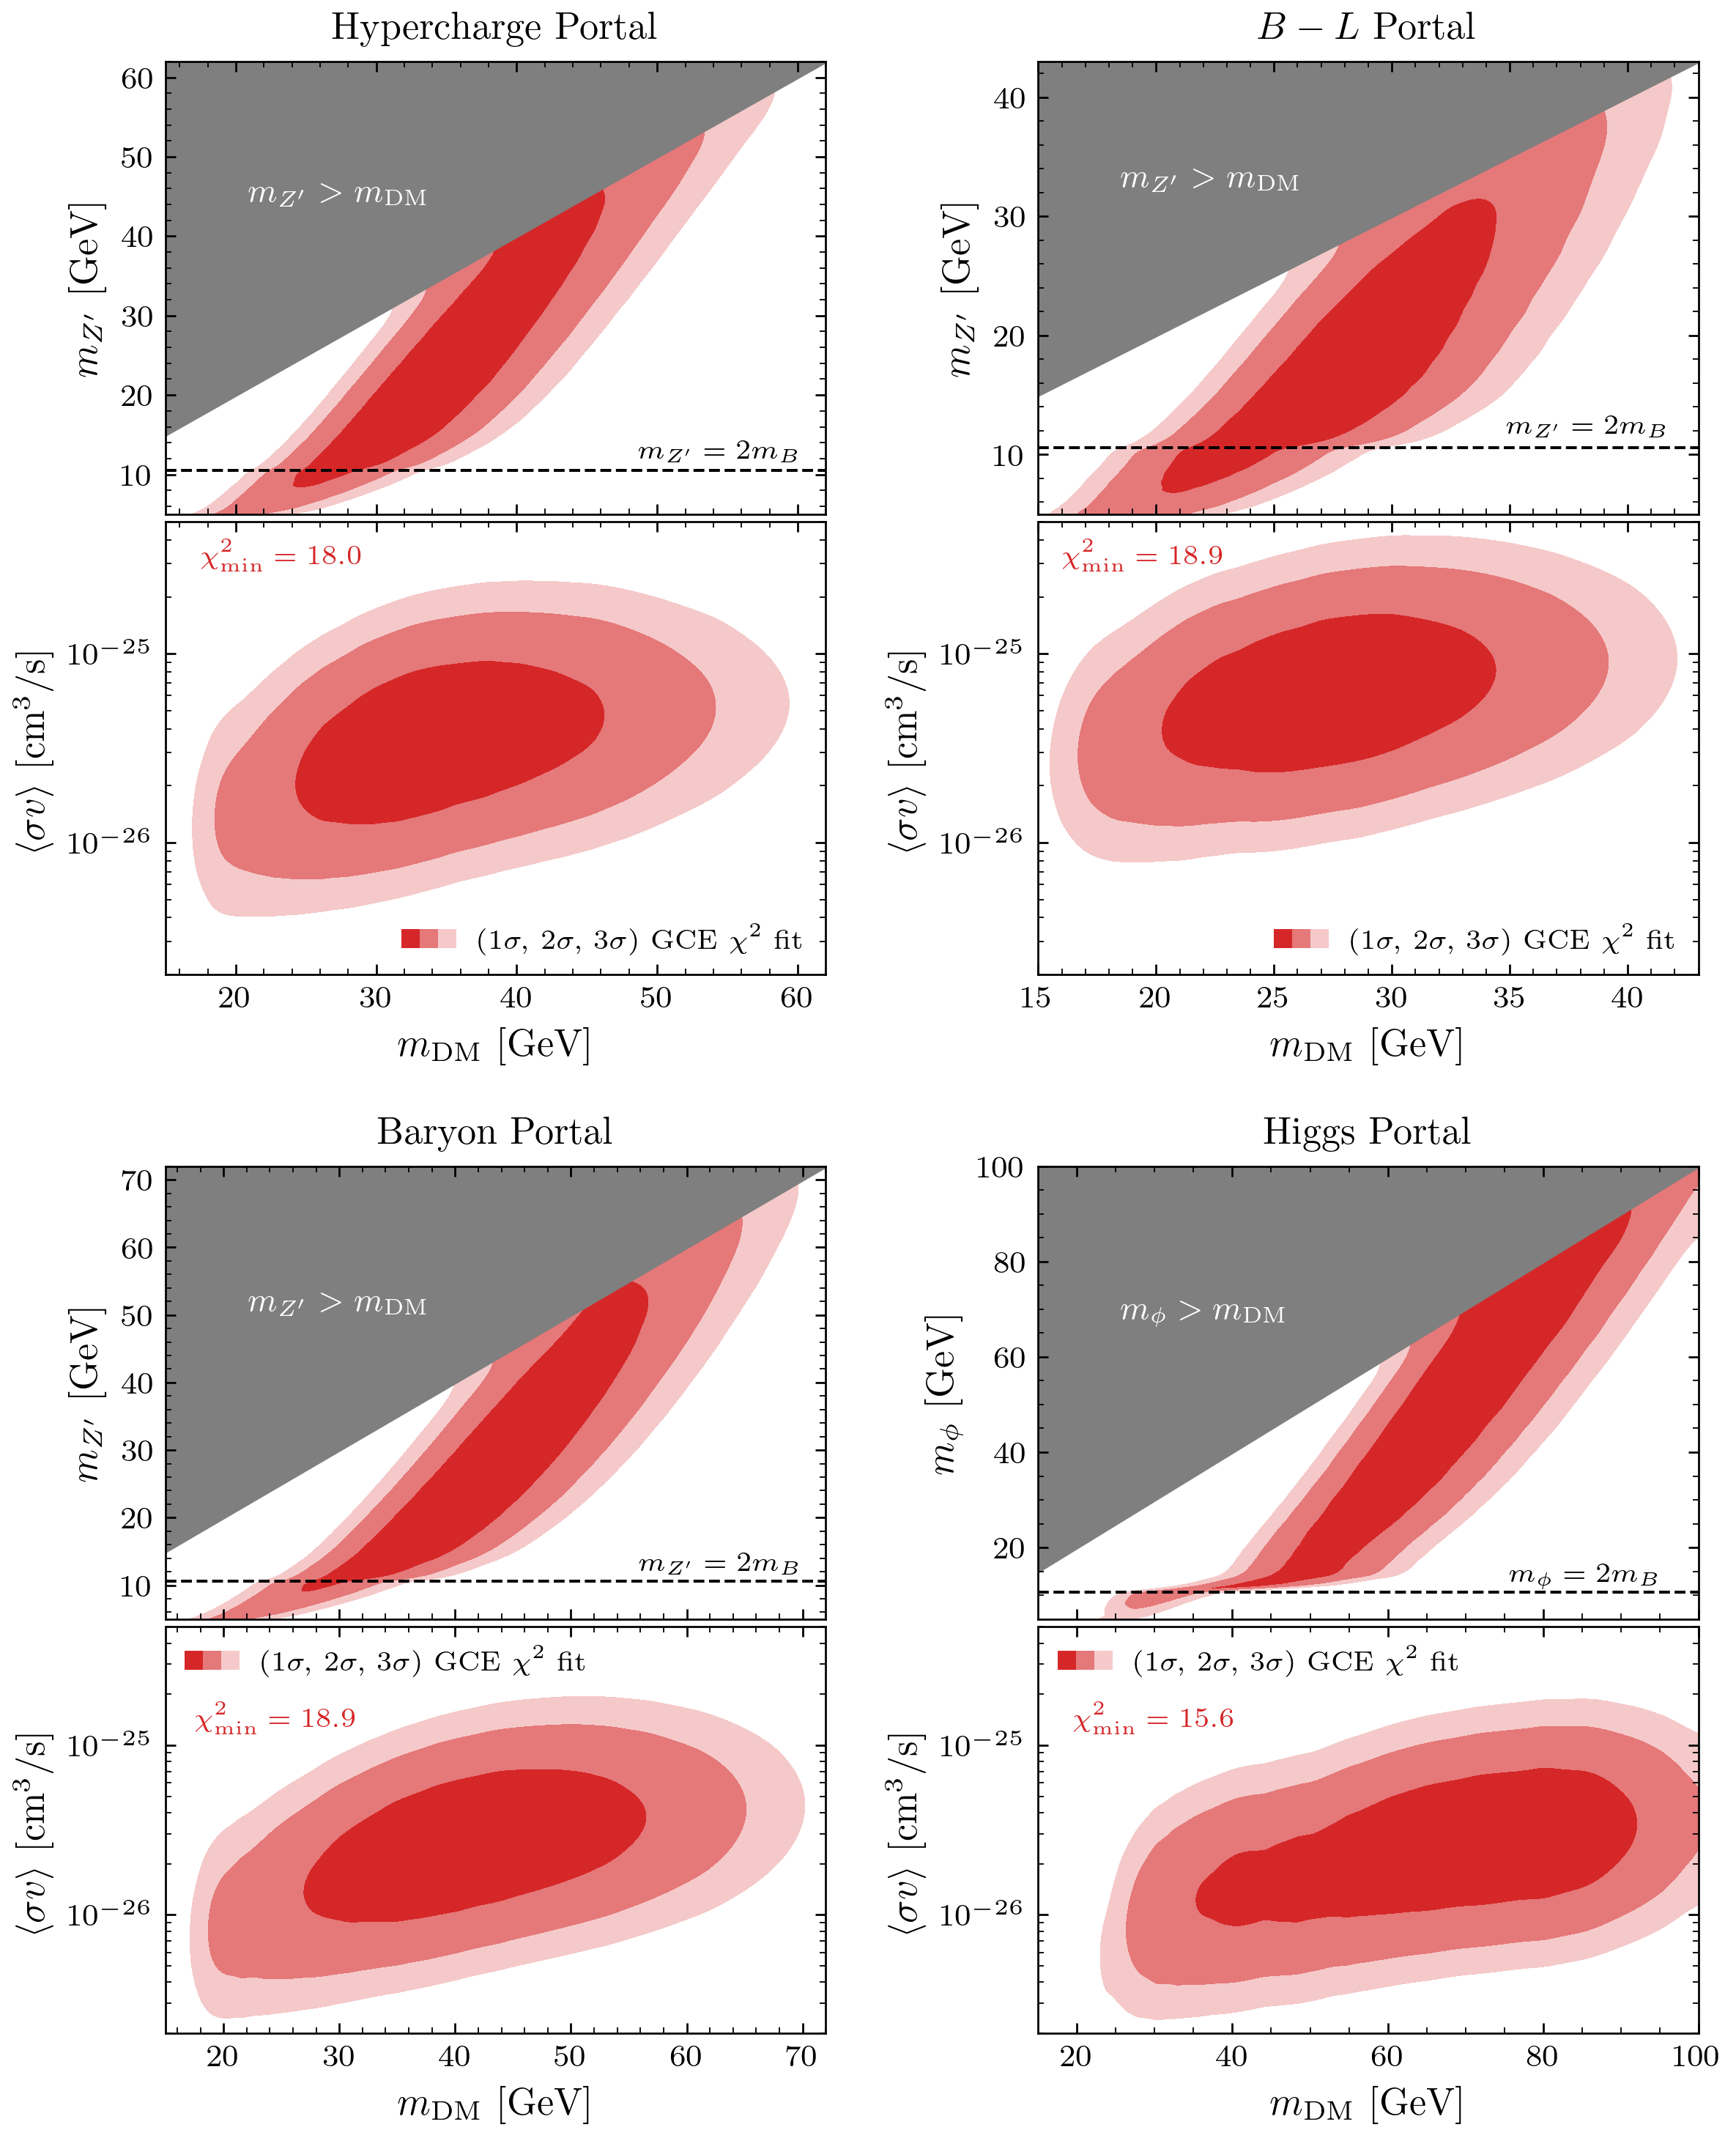

In [163]:
def sv_mX_mY_smooth_contours(fit,SIGMA=3, DM_halo_profiled=True):
    mXmY_contour = smoothed_field(MX_GRID, MY_GRID, fit['chi2'] - fit['chi2'][fit['k_best']],sigma=3)
    if DM_halo_profiled:
        dchi2_smooth = gaussian_filter1d(fit['dchi2_profiled'], 1, axis=1, mode="nearest")
    else:
        dchi2_smooth = gaussian_filter1d(fit['dchi2_fixed_halo'], 1, axis=1, mode="nearest")
    mXsV_contour = [mx_columns, sigmav_axis, dchi2_smooth]
    return mXmY_contour, mXsV_contour
    
_GOLDEN_RATIO_=1.61803398875
cs=color_shades('tab:red', 3)
LVs=[0.0, 2.30, 5.99, 9.2]
portal_axes_info={'vP':{'text':[17.5,3e-25,r'Hypercharge Portal'],'mxlims':[15,62],'mylims':[5,62],'leg_loc':4},
                                  'bP':{'text':[17.5,1.3e-25,r'Baryon Portal'],'mxlims':[15,72],'mylims':[5,72], 'leg_loc':2},
                                  'blP':{'text':[16,3e-25,r'$B-L$ Portal'],'mxlims':[15,43],'mylims':[5,43], 'leg_loc':4},
                                  'hP':{'text':[19.5,1.3e-25,r'Higgs Portal'],'mxlims':[15,100],'mylims':[5,100], 'leg_loc':2},
                                 }
from GCE.pythia_runner import HADRON_MASSES
m_thr = 2 * HADRON_MASSES["bb"]          # 2 m_B, the same value the BR cut uses
#label_names=[ 'GCE $\chi^2$ fit', r' + $\rho_{\odot}=0.44\pm 0.13\,{\rm GeV}/{\rm cm}^3$']
fig = plt.figure(figsize=(7.5, 7.5*_GOLDEN_RATIO_*0.8))

gs = GridSpec(43, 23, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax11= fig.add_subplot(gs[:10, :10])
ax12= fig.add_subplot(gs[10:20, :10])
ax21= fig.add_subplot(gs[24:34, :10])
ax22= fig.add_subplot(gs[34:44, :10])
ax31= fig.add_subplot(gs[:10, 13:])
ax32= fig.add_subplot(gs[10:20, 13:])
ax41= fig.add_subplot(gs[24:34, 13:])
ax42= fig.add_subplot(gs[34:44, 13:])

axs1=[ax11,ax21,ax31,ax41]
axs2=[ax12,ax22,ax32,ax42]

mDMs=np.linspace(5,100,100)
for i in range(len(axs1)):
    axs1[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    CL1, CL2= sv_mX_mY_smooth_contours(fits[portals[i]])
    axs1[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs, alpha=1)
    axs2[i].contourf(CL2[0],CL2[1],CL2[2], levels=LVS,colors=cs, alpha=1)
    axs2[i].set_yscale("log")
    axs2[i].set_ylim(2e-27,5e-25)
    axs2[i].set_ylabel(r"$\langle \sigma v\rangle\,\,[{\rm cm}^3/{\rm s}]$")
    axs2[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
    if portals[i]=='hP':
        axs1[i].set_ylabel(r"$m_{\phi}\,\,[{\rm GeV}]$")
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][1]*0.95, m_thr + 0.8, r'$m_\phi = 2m_B$', fontsize=mpl.rcParams['legend.fontsize'], ha='right', va='bottom')
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/8,
          portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/1.6,
          r"$m_{\phi}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize']*1.2, ha='left')
    else:
        axs1[i].set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][1]*0.97, m_thr + 0.8, r'$m_{Z^\prime} = 2m_B$', fontsize=mpl.rcParams['legend.fontsize'], ha='right', va='bottom')
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/8,
          portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize']*1.2, ha='left')
    axs1[i].set_title(portal_axes_info[portals[i]]['text'][2], fontsize=mpl.rcParams['axes.labelsize'])
    axs2[i].text(portal_axes_info[portals[i]]['text'][0],portal_axes_info[portals[i]]['text'][1], rf"$\chi^2_{{\rm min}}={float(fits[portals[i]]['chi2'][fits[portals[i]]['k_best']]):.1f}$",  color=cs[0], fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs2[i].legend(
    handles=[(Patch(facecolor=cs[0]),Patch(facecolor=cs[1]),Patch(facecolor=cs[2]))],
    labels=[r'$(1\sigma,\,2\sigma,\,3\sigma)$ GCE $\chi^2$ fit'],
    loc=portal_axes_info[portals[i]]['leg_loc'],
    fontsize=mpl.rcParams['legend.fontsize'],
    handler_map={tuple: mpl.legend_handler.HandlerTuple(ndivide=None, pad=0.0)},
    )
    axs2[i].set_xlim(portal_axes_info[portals[i]]['mxlims'][0],portal_axes_info[portals[i]]['mxlims'][1])
    axs1[i].set_xlim(portal_axes_info[portals[i]]['mxlims'][0],portal_axes_info[portals[i]]['mxlims'][1])

    axs1[i].set_xticklabels([])
    axs1[i].set_ylim(portal_axes_info[portals[i]]['mylims'][0],portal_axes_info[portals[i]]['mylims'][1])
    axs1[i].axhline(m_thr, c='k', ls='--', lw=0.8, zorder=3)
plt.savefig("../paper_figs/GCE_fits_v0.png")
plt.savefig("../paper_figs/GCE_fits_v0.pdf")
plt.show()
plt.close()

In [164]:
# ---- relic <sigma v> below the thermalisation floor, eps < eps_therm ------
# Coarse (log10 mX, log10 rv) grids from GCE/scripts/make_relic_grid*.py, copied
# into SV_RELIC_DIR.  Each joint eps has its own file; the secluded eps share one
# (one freeze-out, three dilutions) with eps as the leading axis.
EPS_JOINT    = (1e-9, 1e-10)
EPS_SECLUDED = (1e-11, 5e-12, 1e-12)

# s-wave <sigma v>(mX, mY, coupling) in closed form; it vectorises, so no model per
# grid point.  vP, bP and blP share the hidden sector, so all three call the
# vector-portal form in alpha_X; the hP grid's coupling is lam, which sets lam_s = lam_p
SV_SWAVE = {'vP':  VectorPortal._sigmav_XX_to_YY_swave,
            'bP':  VectorPortal._sigmav_XX_to_YY_swave,
            'blP': VectorPortal._sigmav_XX_to_YY_swave,
            'hP':  lambda mX, mY, lam: HiggsPortal._sigmav_XX_to_YY_swave(mX, mY, lam, lam)}

def coupling_relic_at_eps(name, eps):
    """Coupling (alpha_X, or lam for hP) for Omega_c h^2 = 0.12 at `eps`, interpolated
    in log10 from the coarse grid onto (MX_GRID, MY_GRID); NaN outside the coarse
    hull (rv > 0.95)."""
    if eps in EPS_SECLUDED:
        relic = np.load(SV_RELIC_DIR / f'relic_grid_{name}_eps_secluded.npz')
        # exact equality: np.isclose's default atol=1e-8 exceeds every eps here
        coupling_c = relic['coupling_relic'][int(np.flatnonzero(relic['eps'] == eps)[0])]
    else:
        relic = np.load(SV_RELIC_DIR / f'relic_grid_{name}_eps{eps:.0e}.npz')
        coupling_c = relic['coupling_relic']
    n_domain = int(np.isfinite(relic['mX_grid']).sum())
    if int(relic['n_done']) < n_domain:
        print(f"WARNING {name} eps={eps:.0e}: only {int(relic['n_done'])}/{n_domain} coarse nodes done")

    # keep only nodes whose coupling is an interpolated (not extrapolated) read
    # of the sampled Omega h^2(coupling) curve
    axis = relic['coupling_axis']
    ok_c = np.isfinite(coupling_c) & (coupling_c >= axis.min()) & (coupling_c <= axis.max())
    lmx_c, lrv_c = np.meshgrid(relic['log_mX'], relic['log_rv'], indexing='ij')
    return 10.0 ** griddata(np.column_stack([lmx_c[ok_c], lrv_c[ok_c]]), np.log10(coupling_c[ok_c]),
                            np.column_stack([np.log10(MX_GRID), np.log10(MY_GRID / MX_GRID)]),
                            method='linear')

def sv_relic_at_eps(name, eps):
    coupling = coupling_relic_at_eps(name, eps)
    ok = np.isfinite(coupling)
    sv_relic = np.full(n_pts, np.nan)
    sv_relic[ok] = SV_SWAVE[name](MX_GRID[ok], MY_GRID[ok], coupling[ok]) * GEVM2_TO_CM3S
    return {'coupling_relic': coupling, 'sigmav_relic': sv_relic}

fits_relic_eps = {name: {eps: sv_relic_at_eps(name, eps) for eps in EPS_JOINT + EPS_SECLUDED}
                  for name in portals}
for name, by_eps in fits_relic_eps.items():
    for eps, relic in by_eps.items():
        relic['dchi2_fixed_halo'], relic['dchi2_profiled'] = sv_relic_region(relic, fits[name])
        print(f"{name:4s} eps={eps:.0e}: {np.isfinite(relic['sigmav_relic']).sum():5d} points, "
              f"min dchi2 = {np.nanmin(relic['dchi2_fixed_halo']):.2f} (rho fixed), "
              f"{np.nanmin(relic['dchi2_profiled']):.2f} (rho profiled)")

vP   eps=1e-09: 15759 points, min dchi2 = 31.82 (rho fixed), 6.65 (rho profiled)
vP   eps=1e-10: 15759 points, min dchi2 = 8.17 (rho fixed), 1.78 (rho profiled)
vP   eps=1e-11: 15759 points, min dchi2 = 0.47 (rho fixed), 0.32 (rho profiled)
vP   eps=5e-12: 15759 points, min dchi2 = 0.65 (rho fixed), 0.60 (rho profiled)
vP   eps=1e-12: 15759 points, min dchi2 = 2.02 (rho fixed), 1.32 (rho profiled)
bP   eps=1e-09: 15759 points, min dchi2 = 137.85 (rho fixed), 6.97 (rho profiled)
bP   eps=1e-10: 15759 points, min dchi2 = 36.84 (rho fixed), 4.01 (rho profiled)
bP   eps=1e-11: 15759 points, min dchi2 = 0.17 (rho fixed), 0.05 (rho profiled)
bP   eps=5e-12: 15759 points, min dchi2 = 0.49 (rho fixed), 0.41 (rho profiled)
bP   eps=1e-12: 15706 points, min dchi2 = 2.17 (rho fixed), 1.38 (rho profiled)
blP  eps=1e-09: 15759 points, min dchi2 = 0.96 (rho fixed), 0.57 (rho profiled)
blP  eps=1e-10: 15759 points, min dchi2 = 12.49 (rho fixed), 2.05 (rho profiled)
blP  eps=1e-11: 15759 points, min d

In [165]:
def relic_mX_mY_smooth_contours(relic, SIGMA=2.5, DM_halo_profiled=True):
    if DM_halo_profiled:
        dchi2 = relic['dchi2_profiled']
    else:
        dchi2=relic['dchi2_fixed_halo']
    fin = np.isfinite(dchi2)
    mXmY_contour = smoothed_field(MX_GRID[fin], MY_GRID[fin], dchi2[fin], sigma=SIGMA, rezero=False)
    return mXmY_contour

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:01<00:00,  2.70it/s]


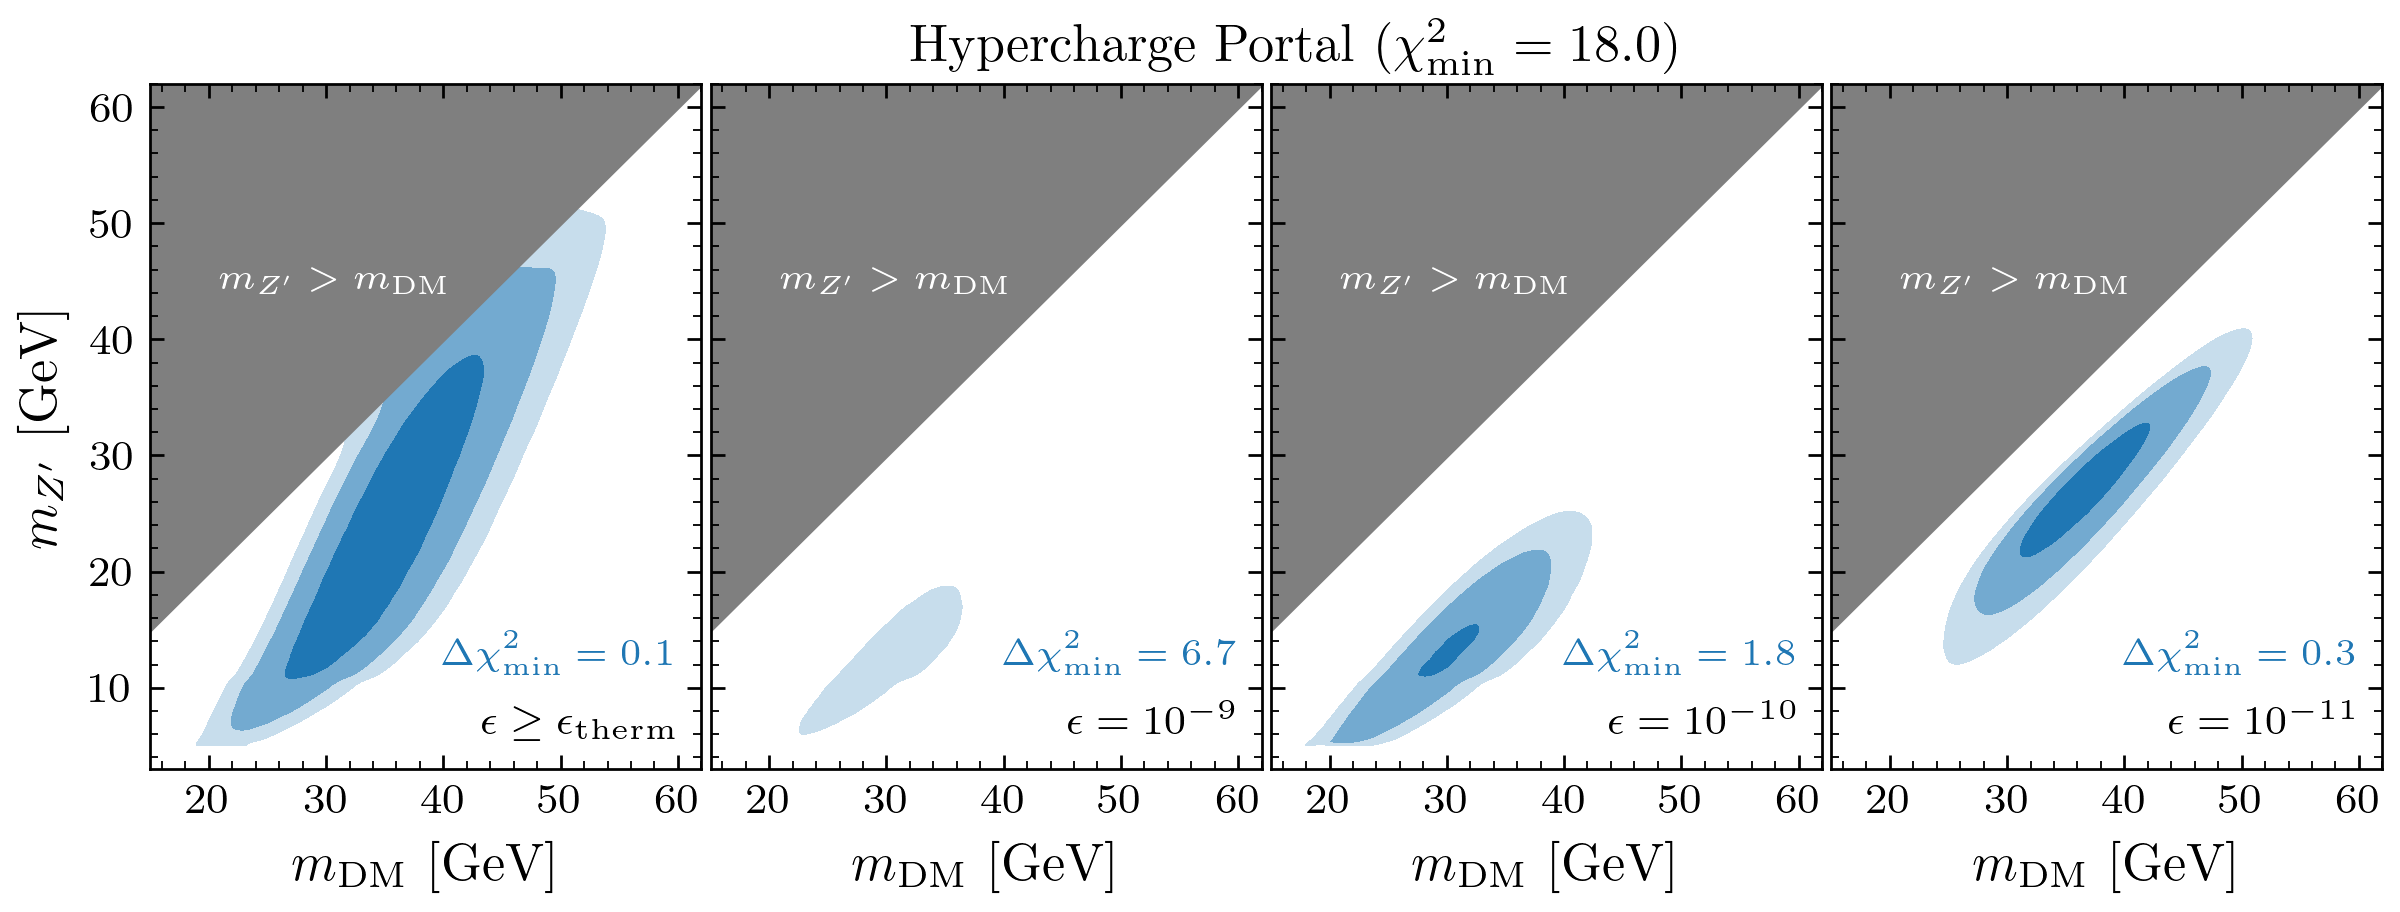

In [141]:
vP_fits=[fits_relic['vP'], fits_relic_eps['vP'][1e-9], fits_relic_eps['vP'][1e-10], fits_relic_eps['vP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(2*_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:, :10])
ax2= fig.add_subplot(gs[:,10:20])
ax3= fig.add_subplot(gs[:,20:30])
ax4= fig.add_subplot(gs[:,30:])
axs=[ax1,ax2,ax3,ax4]
for i in trange(len(axs)):
    axs[i].set_xlim(15,62)
    axs[i].set_xticks([20,30,40,50,60])
    axs[i].set_ylim(3, 62)
    axs[i].set_yticks([10,20,30,40,50,60])
    if i!=0:
        axs[i].set_yticklabels([])
    CL1=relic_mX_mY_smooth_contours(vP_fits[i])
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/8,
          portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(60,6,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(60,12, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(vP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax2.text(32,64,r"Hypercharge Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['vP']['chi2'][fits['vP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
plt.savefig("../paper_figs/GCE_fits_vP_secluded_v0.png")
plt.savefig("../paper_figs/GCE_fits_vP_secluded_v0.pdf")
plt.show()
plt.close()

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:01<00:00,  2.95it/s]


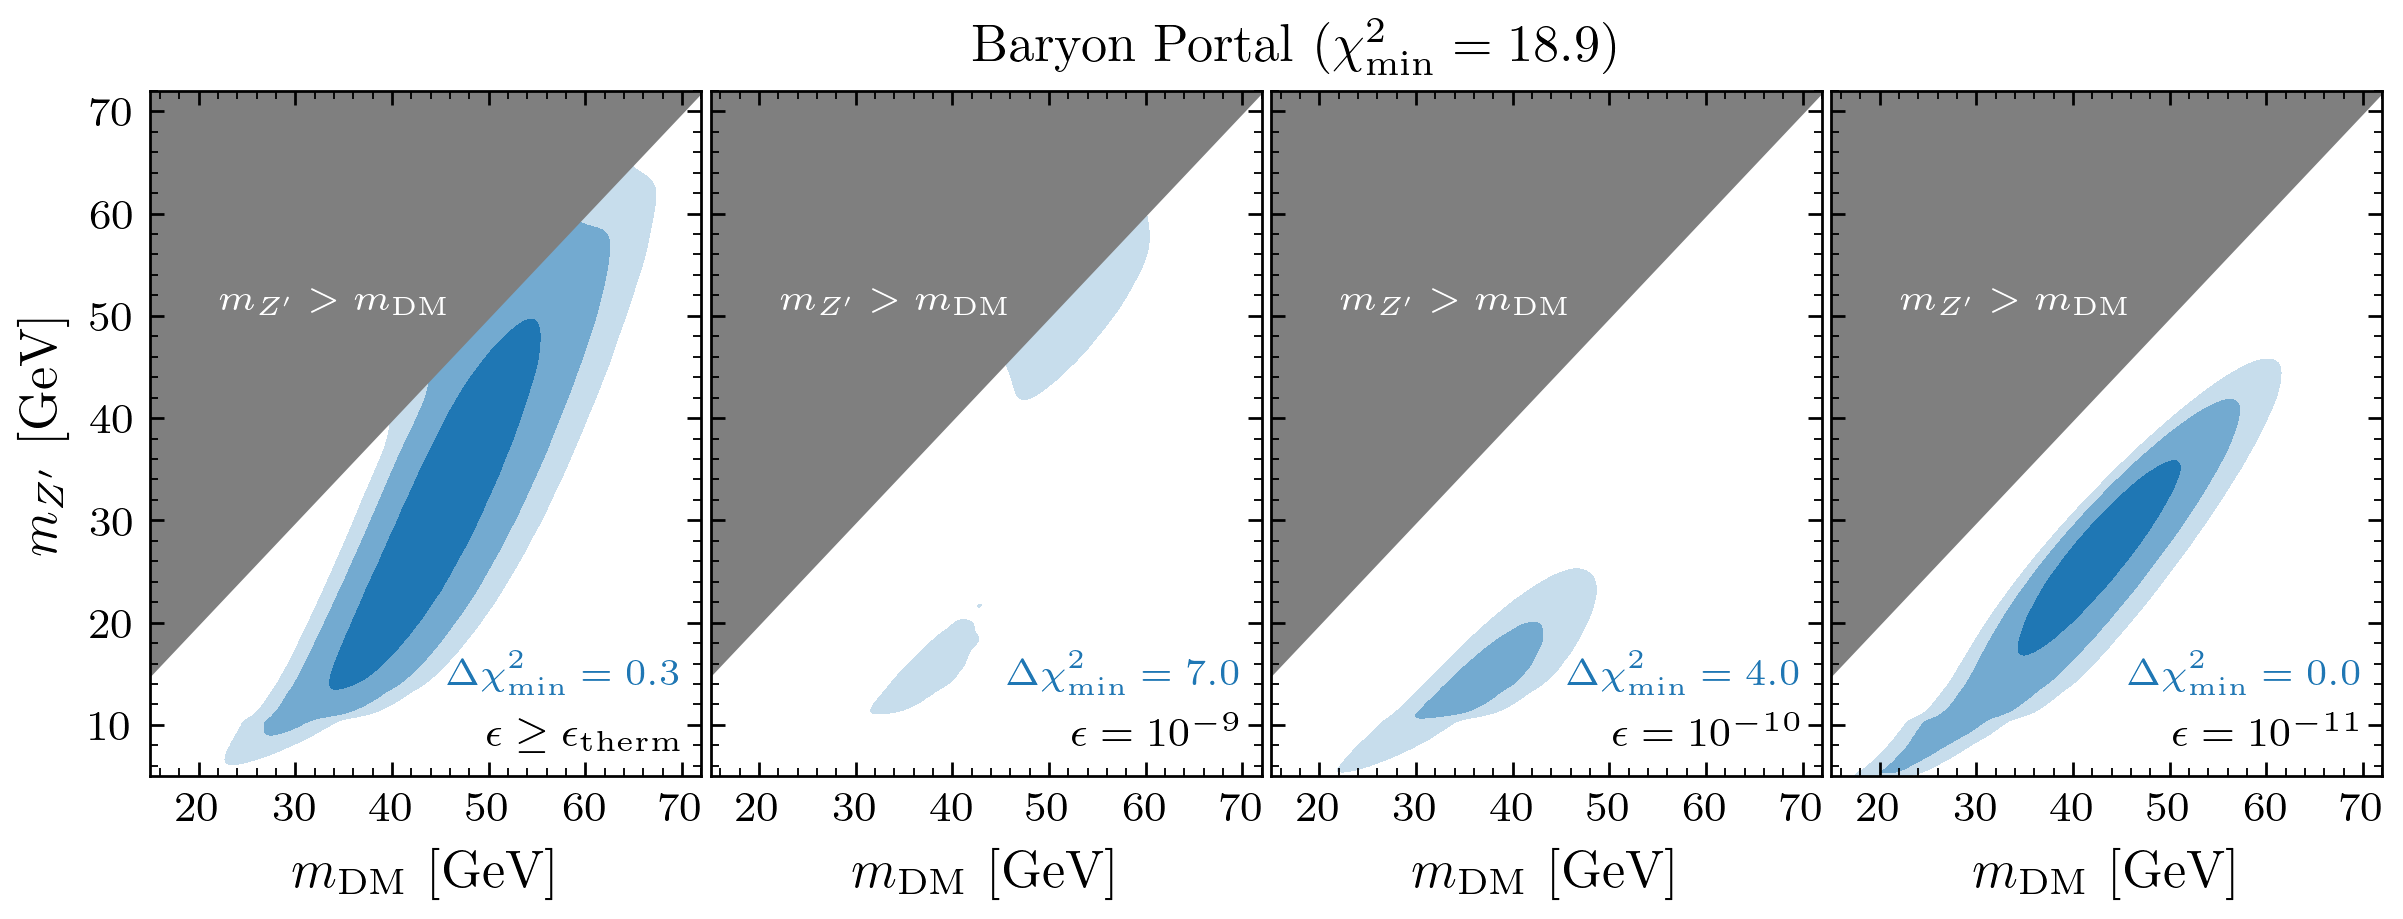

In [149]:
bP_fits=[fits_relic['bP'], fits_relic_eps['bP'][1e-9], fits_relic_eps['bP'][1e-10], fits_relic_eps['bP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(2*_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:, :10])
ax2= fig.add_subplot(gs[:,10:20])
ax3= fig.add_subplot(gs[:,20:30])
ax4= fig.add_subplot(gs[:,30:])
axs=[ax1,ax2,ax3,ax4]
for i in trange(len(axs)):
    axs[i].set_xlim(15,72)
    axs[i].set_xticks([20,30,40,50,60,70])
    axs[i].set_ylim(5, 72)
    axs[i].set_yticks([10,20,30,40,50,60,70])
    if i!=0:
        axs[i].set_yticklabels([])
    CL1=relic_mX_mY_smooth_contours(bP_fits[i])
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['bP']['mxlims'][0]+(portal_axes_info['bP']['mxlims'][1]-portal_axes_info['bP']['mxlims'][0])/8,
          portal_axes_info['bP']['mxlims'][0]+(portal_axes_info['bP']['mxlims'][1]-portal_axes_info['bP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(70,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(70,14, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(bP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax2.text(42,75, r"Baryon Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['bP']['chi2'][fits['bP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
plt.savefig("../paper_figs/GCE_fits_bP_secluded_v0.png")
plt.savefig("../paper_figs/GCE_fits_bP_secluded_v0.pdf")
plt.show()
plt.close()

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:01<00:00,  2.91it/s]


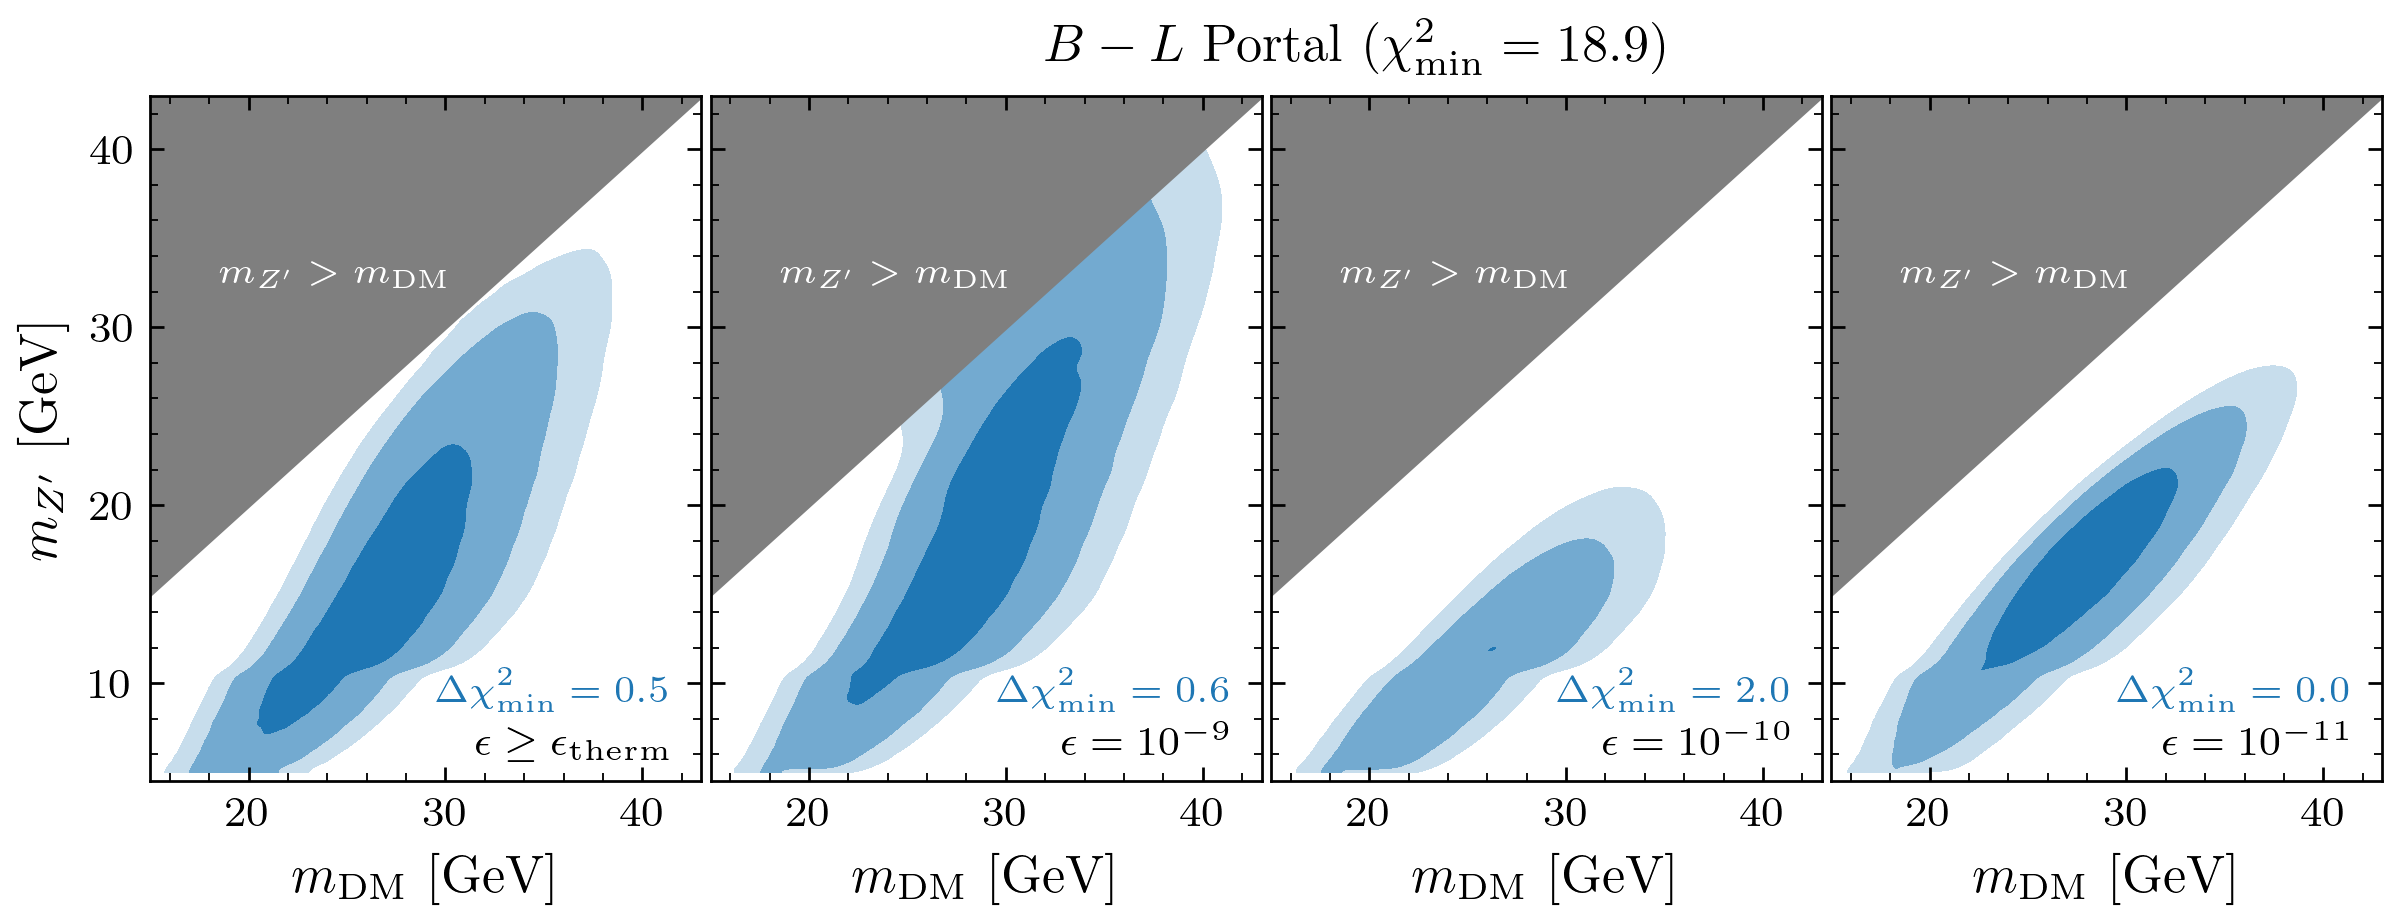

In [157]:
blP_fits=[fits_relic['blP'], fits_relic_eps['blP'][1e-9], fits_relic_eps['blP'][1e-10], fits_relic_eps['blP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(2*_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:, :10])
ax2= fig.add_subplot(gs[:,10:20])
ax3= fig.add_subplot(gs[:,20:30])
ax4= fig.add_subplot(gs[:,30:])
axs=[ax1,ax2,ax3,ax4]
for i in trange(len(axs)):
    axs[i].set_xlim(15,43)
    axs[i].set_xticks([20,30,40])
    axs[i].set_ylim(4.5, 43)
    axs[i].set_yticks([10,20,30,40])
    if i!=0:
        axs[i].set_yticklabels([])
    CL1=relic_mX_mY_smooth_contours(blP_fits[i])
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['blP']['mxlims'][0]+(portal_axes_info['blP']['mxlims'][1]-portal_axes_info['blP']['mxlims'][0])/8,
          portal_axes_info['blP']['mxlims'][0]+(portal_axes_info['blP']['mxlims'][1]-portal_axes_info['blP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(41.5,6,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(41.5,9, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(blP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax2.text(32,45,r"$B-L$ Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['blP']['chi2'][fits['blP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
plt.savefig("../paper_figs/GCE_fits_blP_secluded_v0.png")
plt.savefig("../paper_figs/GCE_fits_blP_secluded_v0.pdf")
plt.show()
plt.close()

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:01<00:00,  3.63it/s]


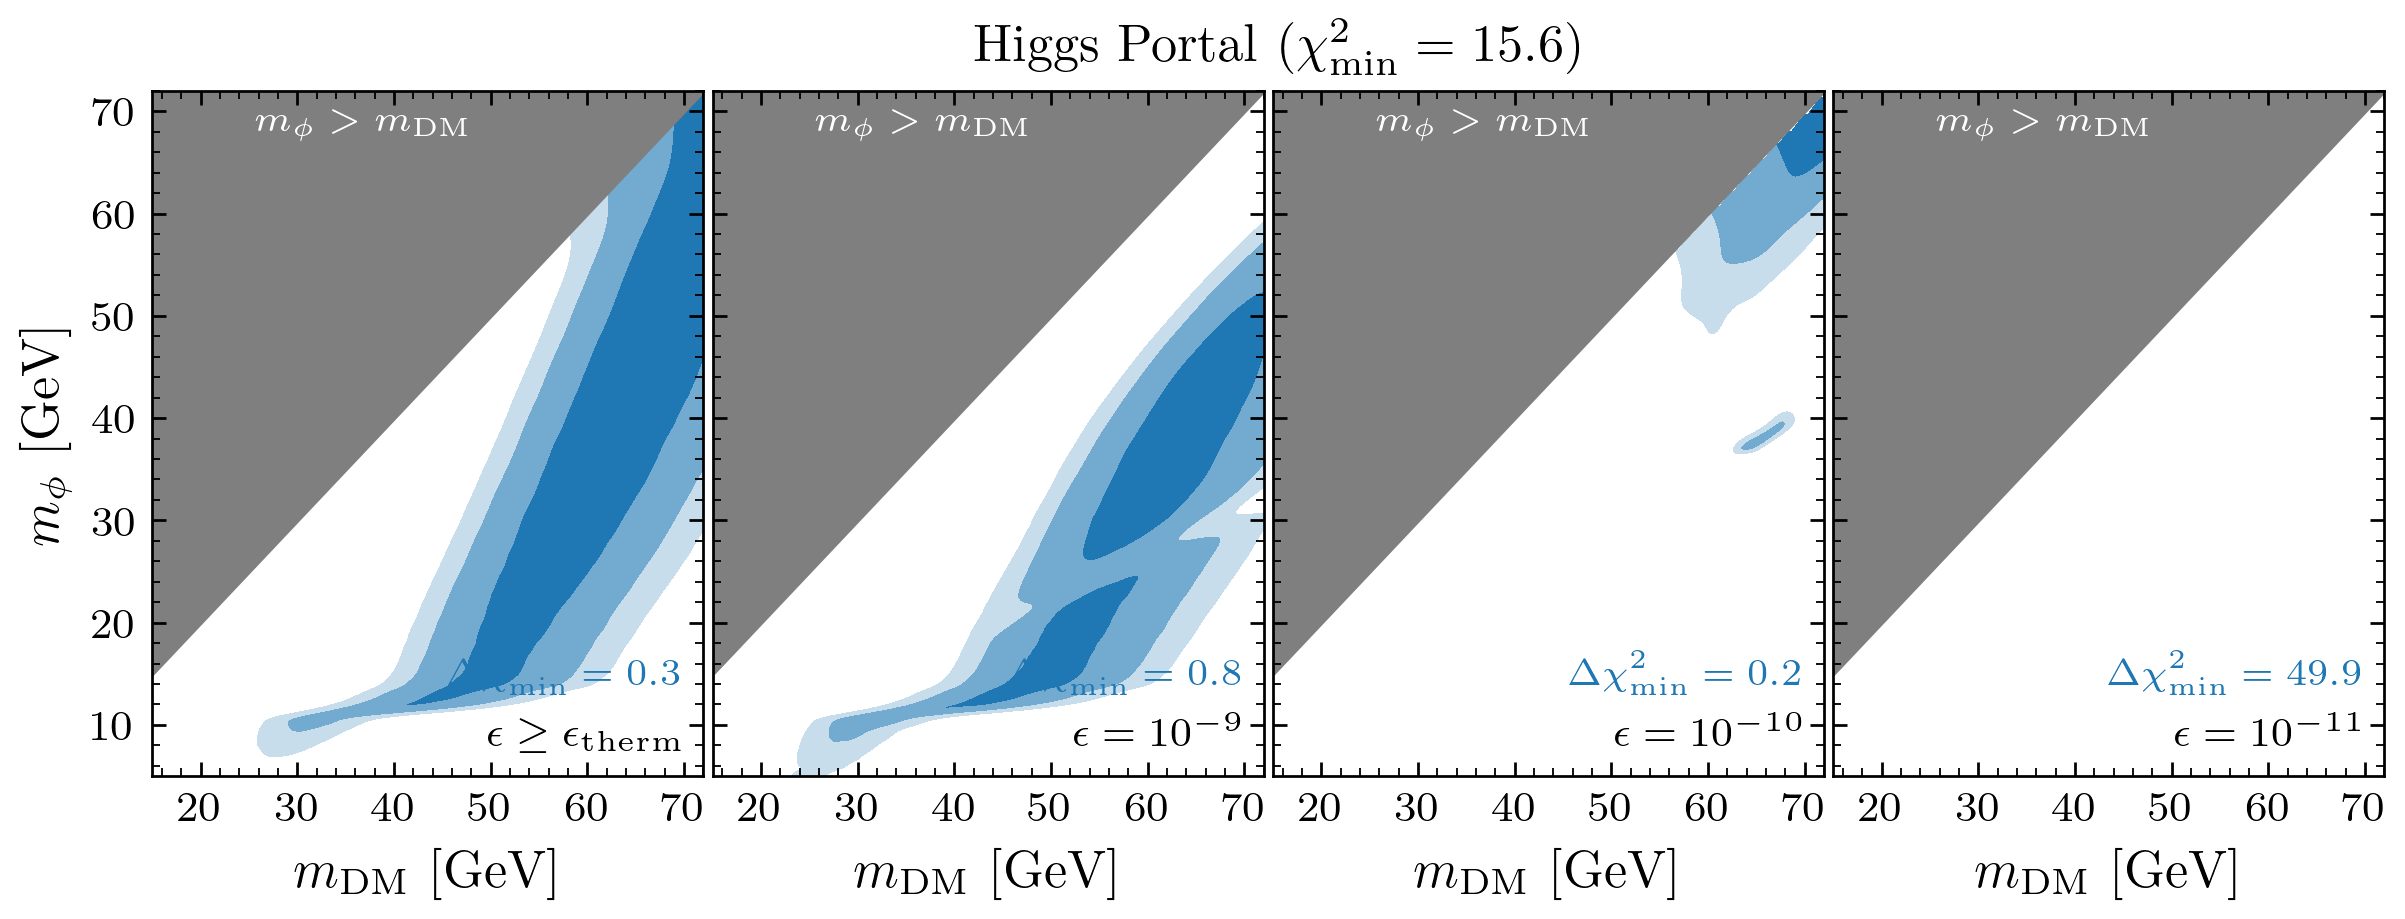

In [168]:
hP_fits=[fits_relic['hP'], fits_relic_eps['hP'][1e-9], fits_relic_eps['hP'][1e-10], fits_relic_eps['hP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(2*_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:, :10])
ax2= fig.add_subplot(gs[:,10:20])
ax3= fig.add_subplot(gs[:,20:30])
ax4= fig.add_subplot(gs[:,30:])
axs=[ax1,ax2,ax3,ax4]
for i in trange(len(axs)):
    axs[i].set_xlim(15,72)
    axs[i].set_xticks([20,30,40,50,60,70])
    axs[i].set_ylim(5, 72)
    axs[i].set_yticks([10,20,30,40,50,60,70])
    if i!=0:
        axs[i].set_yticklabels([])
    CL1=relic_mX_mY_smooth_contours(hP_fits[i])
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['hP']['mxlims'][0]+(portal_axes_info['hP']['mxlims'][1]-portal_axes_info['hP']['mxlims'][0])/8,
          portal_axes_info['hP']['mxlims'][0]+(portal_axes_info['hP']['mxlims'][1]-portal_axes_info['hP']['mxlims'][0])/1.6,
          r"$m_{\phi}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(70,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(70,14, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(hP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{\phi}\,\,[{\rm GeV}]$")
ax2.text(42,75, r"Higgs Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['hP']['chi2'][fits['hP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
#plt.savefig("../paper_figs/GCE_fits_hP_secluded_v0.png")
#plt.savefig("../paper_figs/GCE_fits_hP_secluded_v0.pdf")
plt.show()
plt.close()